## 1. Импорты и чтение датасета
Выполняем все те же операции, что и в бейслайне

In [1]:
# Необходимо для корректной работы внешних .py файлов
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import random
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, TargetEncoder
from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from helper import *
from plots import *
from sklearn.preprocessing import StandardScaler, MinMaxScaler


In [3]:
# фиксируем состояние генератора псевдослучайных чисел. Это необходимо, чтобы результаты модели не менялись с каждым новым запуском 
SEED = 42 # можно указать любое число
np.random.seed(SEED)
random.seed(SEED)

In [4]:
df = pd.read_csv("diamonds.csv")

## 1.1 Предобработка

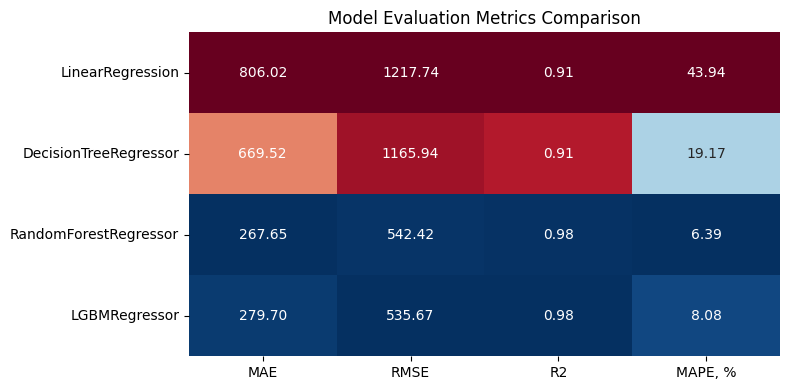

In [5]:
df = df.drop(columns=['Unnamed: 0'])

df_preprocessed = df.copy()
X, y = divide_data(df_preprocessed, 'price')

categorical_cols = ['cut', 'color', 'clarity']
category_orders = [
    ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'],          # cut
    ['J', 'I', 'H', 'G', 'F', 'E', 'D'],                        # color
    ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF'],   # clarity
]

# Пропусков нет, поэтому в препроцессоре только кодирование
preprocessor = ColumnTransformer(
    [('encoder', OrdinalEncoder(categories=category_orders), categorical_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False
)
preprocessor.set_output(transform="pandas")

models = [
    ('LinearRegression', LinearRegression()),
    ('DecisionTreeRegressor', DecisionTreeRegressor(random_state=SEED, max_depth=4)),
    ('RandomForestRegressor', RandomForestRegressor(random_state=SEED, n_jobs=-1)),
    ('LGBMRegressor', LGBMRegressor(random_state=SEED, verbose=-1)),
]

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
initial_metrics = train_evaluate_models_cv_regression(
    models=models, X=X, y=y, preprocessor=preprocessor, cv=cv, seed=SEED
)



## 2. Преобразования данных и feature engineering

### 2.1 Логарифмическое преобразование


#### 2.1.1 Логарифмирование таргета

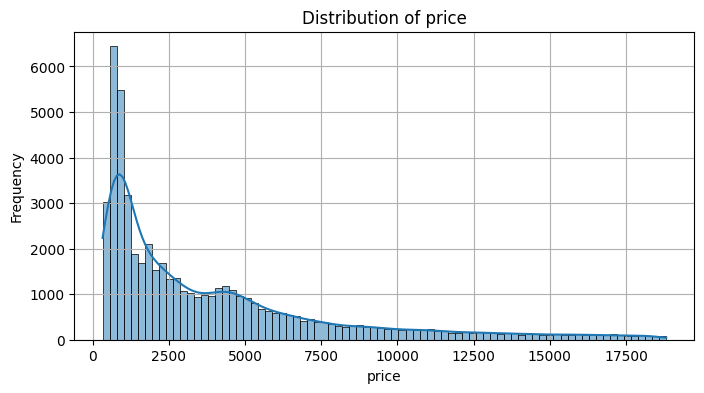

In [6]:
plot_hist_numeric(df, 'price')

Цена имеет сильно скошенное распределение. Логарифм должен сделать его ближе к нормальному, а ошибки будут относительными, а не абсолютными

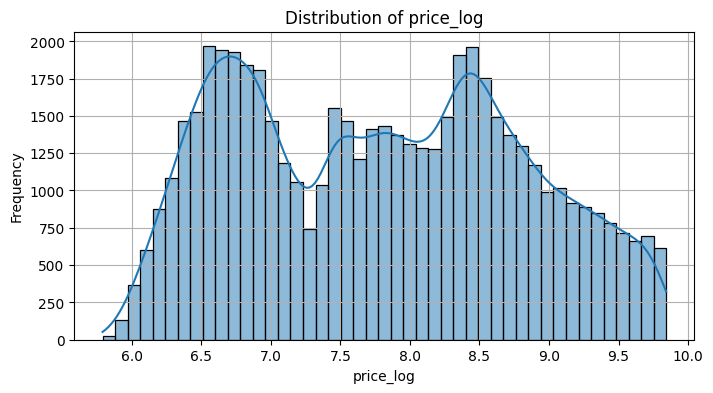

In [7]:
df_log_price = df.assign(price_log=np.log1p(df['price']))
plot_hist_numeric(df_log_price, 'price_log')

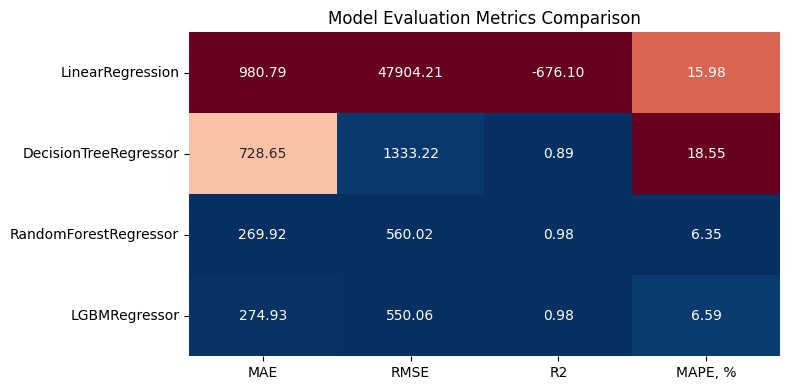

In [8]:
log_target_metrics = train_evaluate_models_cv_regression(
    models=models, X=X, y=y, preprocessor=preprocessor, cv=cv, seed=SEED,
    log_target=True
)

(<Figure size 800x400 with 1 Axes>,
                              MAE         RMSE            R2    MAPE, %
 LinearRegression      -21.683624 -3833.871609 -74659.852731  63.637299
 DecisionTreeRegressor  -8.831773   -14.346807     -2.872998   3.226302
 RandomForestRegressor  -0.847193    -3.244424     -0.124722   0.617855
 LGBMRegressor           1.702893    -2.685288     -0.100257  18.431938)

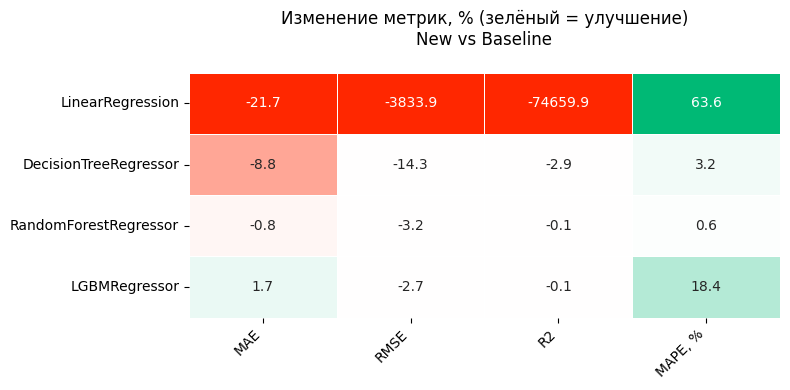

In [9]:
compare_regression_metrics_heatmap(initial_metrics, log_target_metrics)

#### 2.1.2 Без удаления столбцов

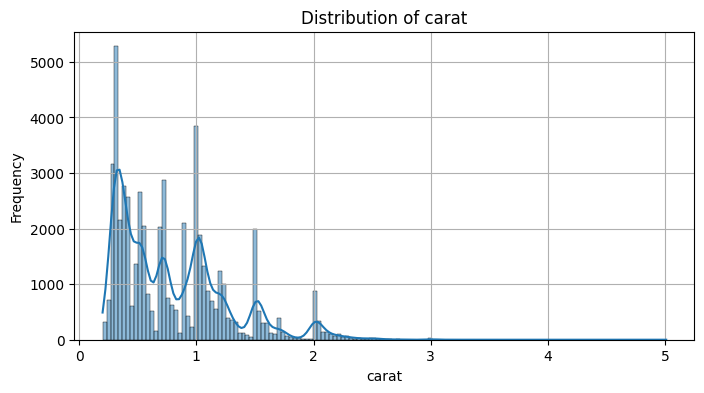

In [10]:
X_log_carat = X.copy()
X_log_carat['carat_log'] = np.log(X_log_carat['carat'])
plot_hist_numeric(X_log_carat, 'carat')


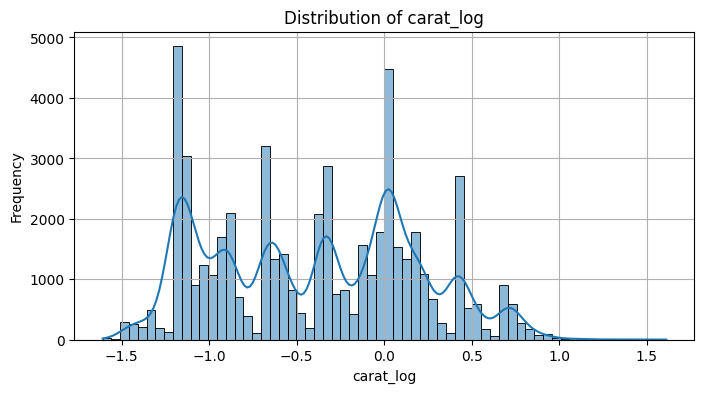

In [11]:
plot_hist_numeric(X_log_carat, 'carat_log')

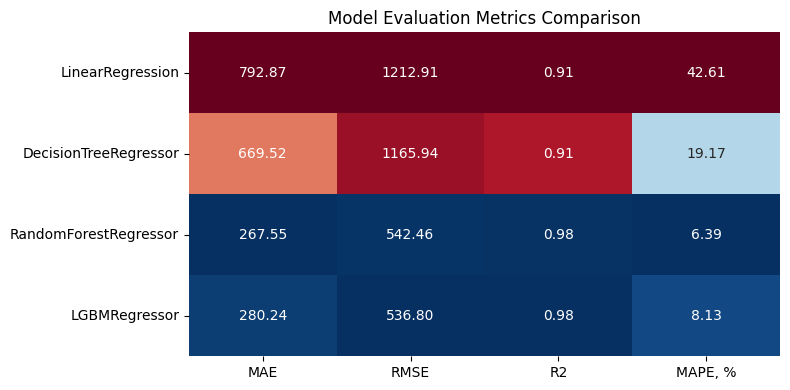

In [12]:
log_carat_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X_log_carat, 
    y=y, 
    preprocessor=preprocessor, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                             MAE      RMSE        R2   MAPE, %
 LinearRegression       1.630432  0.396651  0.081675  3.014283
 DecisionTreeRegressor -0.000000 -0.000000  0.000000 -0.000000
 RandomForestRegressor  0.035823 -0.007365 -0.000360  0.081697
 LGBMRegressor         -0.193390 -0.210181 -0.007863 -0.562407)

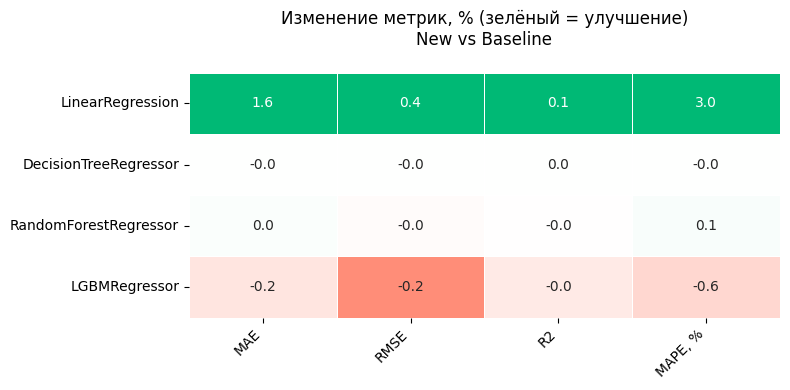

In [13]:
compare_regression_metrics_heatmap(initial_metrics, log_carat_metrics)

#### 2.1.3 С удалением исходных столбцов

In [14]:
X_log_carat_del = X.copy()
X_log_carat_del['carat'] = np.log(X_log_carat_del['carat'])

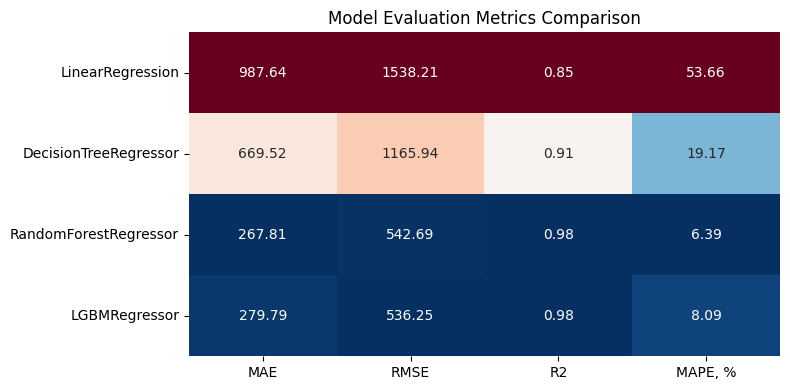

In [15]:
log_carat_del_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X_log_carat_del, 
    y=y, 
    preprocessor=preprocessor, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                              MAE       RMSE        R2    MAPE, %
 LinearRegression      -22.533497 -26.316923 -6.165826 -22.119396
 DecisionTreeRegressor  -0.000000  -0.000000  0.000000  -0.000000
 RandomForestRegressor  -0.060125  -0.049452 -0.001843  -0.051459
 LGBMRegressor          -0.034724  -0.108113 -0.004059  -0.080816)

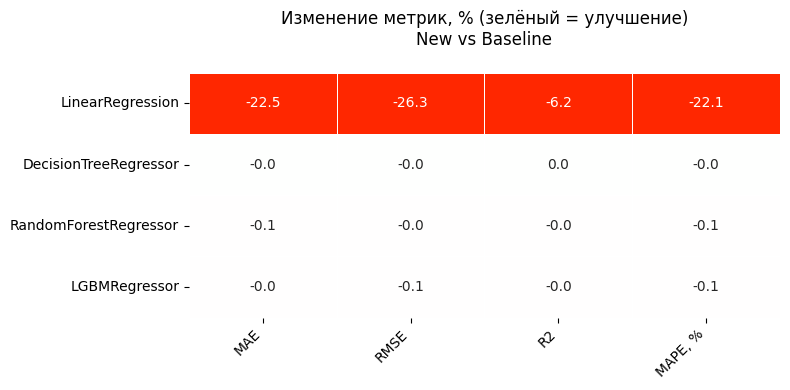

In [16]:
compare_regression_metrics_heatmap(initial_metrics, log_carat_del_metrics)

C удалением столбца линейная регрессия работает хуже

### 2.3 Создание нового признака «volume»

Объём может заменить три коррелирующих признака одним

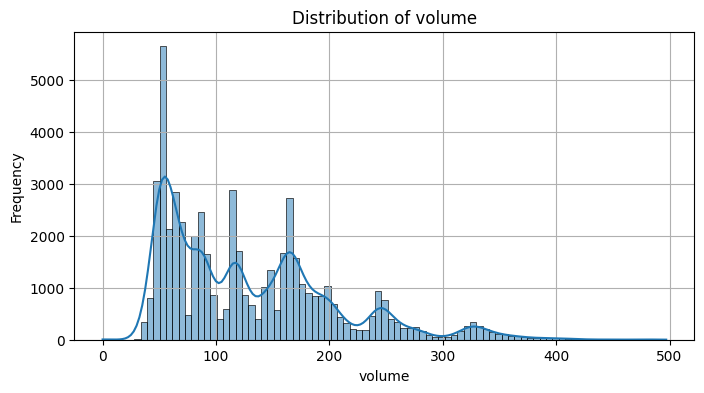

In [17]:
X_volume = X.copy()
X_volume['volume'] = X_volume['x'] * X_volume['y'] * X_volume['z']
plot_hist_numeric(X_volume, 'volume', x_max=500)

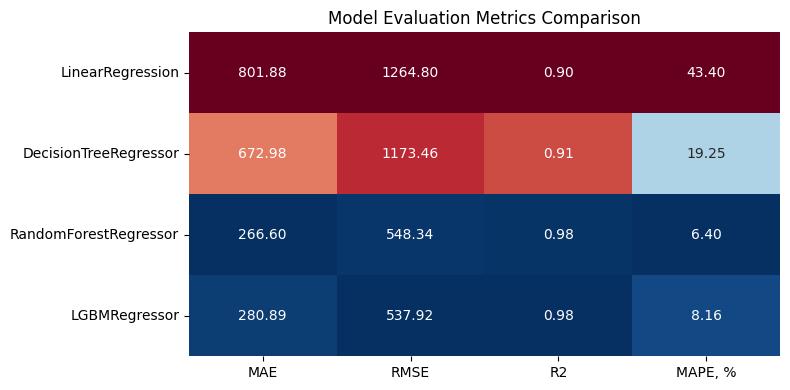

In [18]:
volume_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X_volume, 
    y=y, 
    preprocessor=preprocessor, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                             MAE      RMSE        R2   MAPE, %
 LinearRegression       0.512788 -3.864469 -0.860317  1.232609
 DecisionTreeRegressor -0.516831 -0.644521 -0.121122 -0.436912
 RandomForestRegressor  0.393717 -1.090893 -0.041214 -0.138367
 LGBMRegressor         -0.427715 -0.419810 -0.015556 -0.973493)

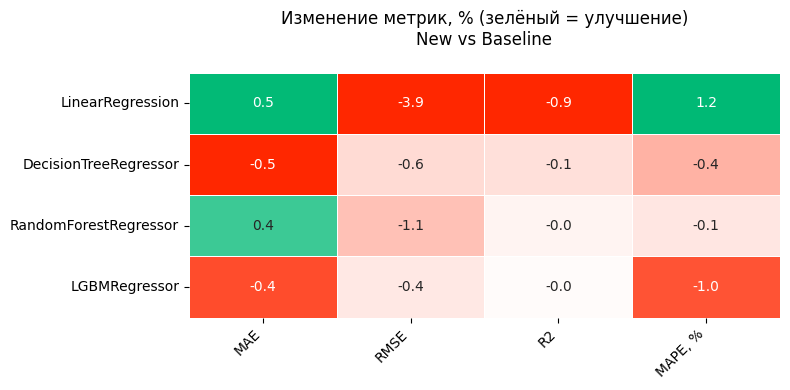

In [19]:
compare_regression_metrics_heatmap(initial_metrics, volume_metrics)

#### 2.3.2 С удалением x, y, z

In [20]:
X_volume_del = X_volume.drop(columns=['x', 'y', 'z'])

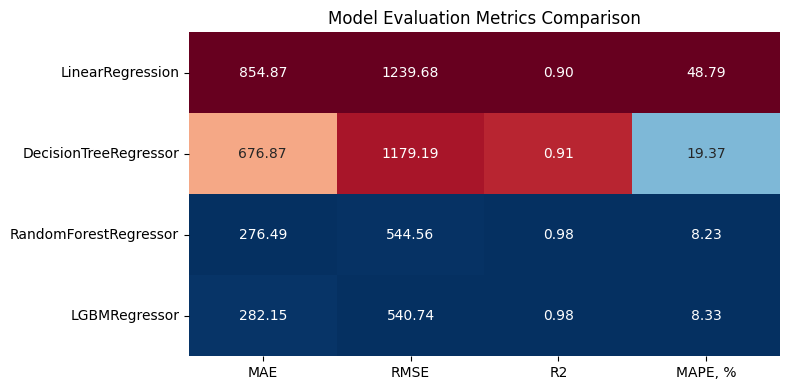

In [21]:
volume_del_metrics = train_evaluate_models_cv_regression(
    models=models, X=X_volume_del, y=y, preprocessor=preprocessor, cv=cv, seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                             MAE      RMSE        R2    MAPE, %
 LinearRegression      -6.061632 -1.801910 -0.371744 -11.050997
 DecisionTreeRegressor -1.098362 -1.136739 -0.214086  -1.076666
 RandomForestRegressor -3.301454 -0.394818 -0.014988 -28.849289
 LGBMRegressor         -0.876013 -0.945773 -0.034973  -3.128960)

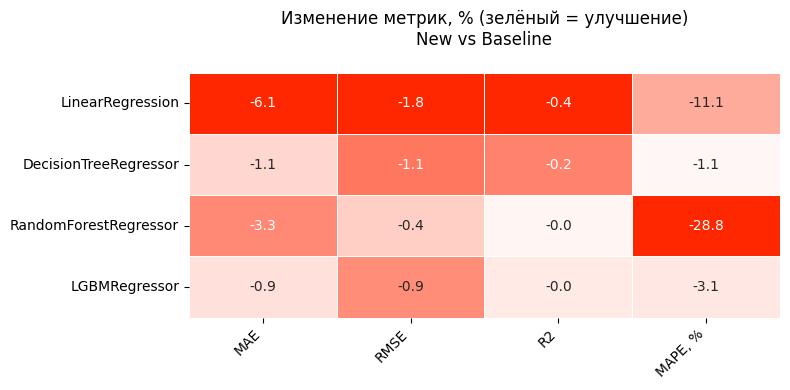

In [22]:
compare_regression_metrics_heatmap(initial_metrics, volume_del_metrics)

Все метрики стали хуже

### 2.4 Биннинг для carat


#### 2.4.1 Без удаления

In [23]:
X_carat_bins = X.copy()

In [24]:
bins = [0, 0.5, 1, 1.5, 2, np.inf]
labels = [0, 1, 2, 3, 4]

X_carat_bins['carat_bins'] = pd.cut(X_carat_bins['carat'], bins=bins, labels=labels).astype(int)

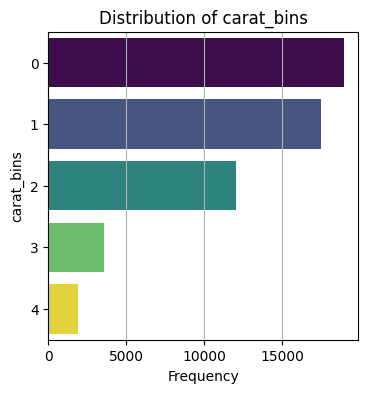

In [25]:
plot_hist_categorical(X_carat_bins, 'carat_bins')

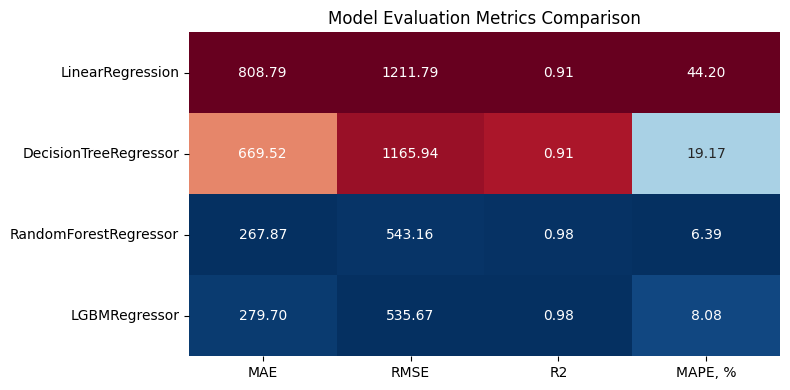

In [26]:
carat_bins_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X_carat_bins, 
    y=y, 
    preprocessor=preprocessor, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                             MAE      RMSE        R2   MAPE, %
 LinearRegression      -0.343712  0.488432  0.100728 -0.591721
 DecisionTreeRegressor -0.000000 -0.000000  0.000000 -0.000000
 RandomForestRegressor -0.080351 -0.135490 -0.005070 -0.030348
 LGBMRegressor         -0.000000 -0.000000  0.000000 -0.000000)

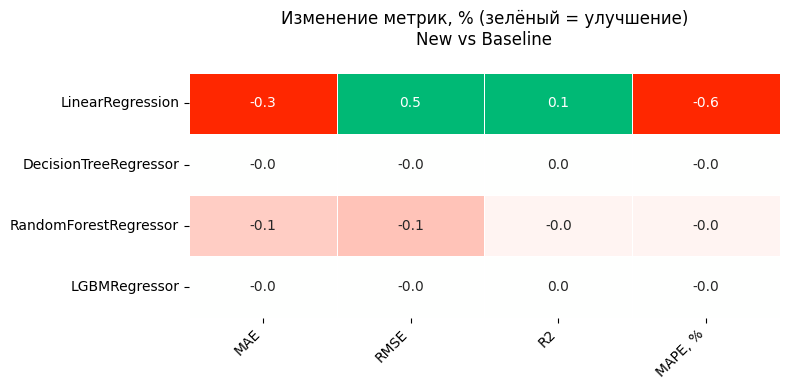

In [27]:
compare_regression_metrics_heatmap(initial_metrics, carat_bins_metrics)

Улучшения не наблюдается

#### 2.4.2 С удалением

In [28]:
X_carat_bins_del = X.copy()
X_carat_bins_del['carat'] = pd.cut(X_carat_bins_del['carat'], bins=bins, labels=labels).astype(int)

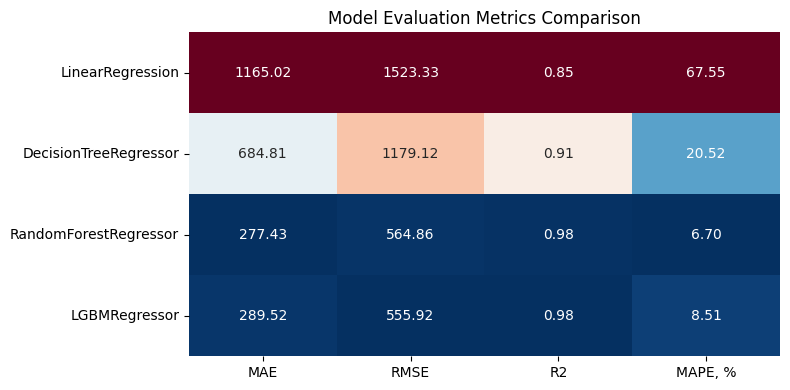

In [29]:
carat_bins_del_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X_carat_bins_del, 
    y=y, 
    preprocessor=preprocessor, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                              MAE       RMSE        R2    MAPE, %
 LinearRegression      -44.540123 -25.095329 -5.801631 -53.738475
 DecisionTreeRegressor  -2.283852  -1.130046 -0.212760  -7.044440
 RandomForestRegressor  -3.654627  -4.137258 -0.159667  -4.834063
 LGBMRegressor          -3.511449  -3.779711 -0.142107  -5.252036)

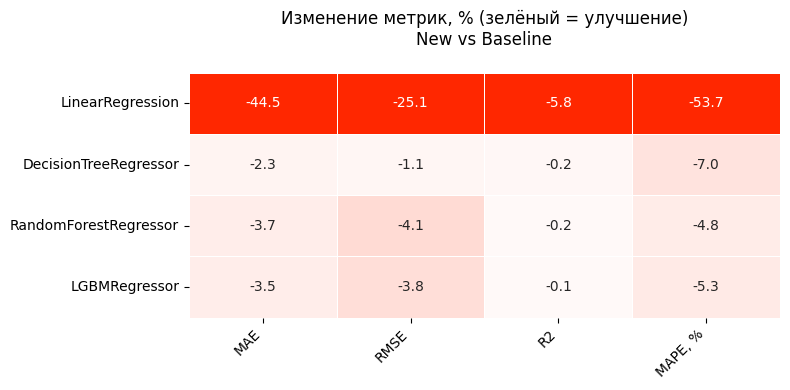

In [30]:
compare_regression_metrics_heatmap(initial_metrics, carat_bins_del_metrics)

(<Figure size 800x400 with 1 Axes>,
                              MAE       RMSE        R2    MAPE, %
 LinearRegression      -44.045022 -25.709333 -5.896420 -52.834123
 DecisionTreeRegressor  -2.283852  -1.130046 -0.212760  -7.044440
 RandomForestRegressor  -3.571406  -3.996353 -0.154605  -4.802258
 LGBMRegressor          -3.511449  -3.779711 -0.142107  -5.252036)

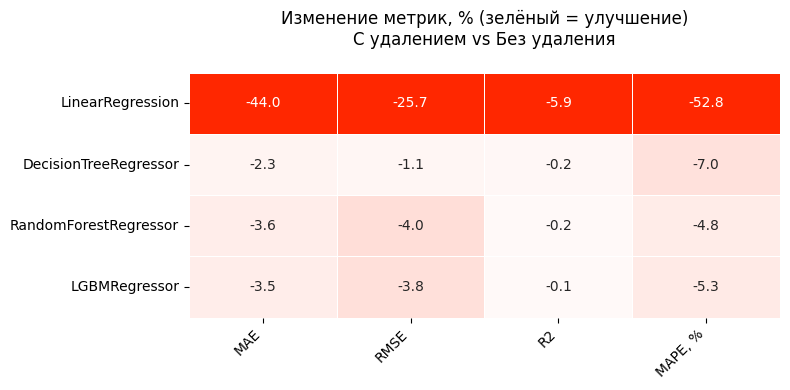

In [ ]:
compare_regression_metrics_heatmap(carat_bins_metrics, carat_bins_del_metrics,
                                   df1_name='Без удаления', df2_name='С удалением')


### 2.5 Применение StandardScaler (стандартизация)

#### 2.5.1 Без удаления

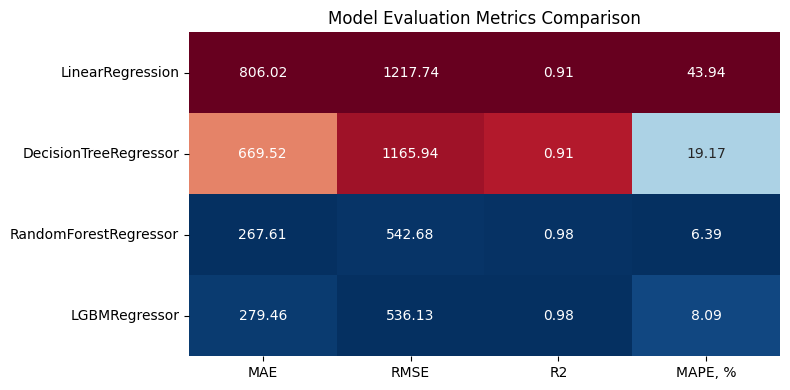

In [32]:
X_standard = X.copy()
numeric_cols = ['carat', 'depth', 'table', 'x', 'y', 'z']
scaled_columns = [f'{c}_scaled' for c in numeric_cols]
X_standard[scaled_columns] = X_standard[numeric_cols]

preprocessor_standard = clone(preprocessor)
preprocessor_standard.transformers.append(
    ('scaler', StandardScaler(), scaled_columns)
)

standard_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X_standard, 
    y=y, 
    preprocessor=preprocessor_standard, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                                 MAE          RMSE        R2       MAPE, %
 LinearRegression      -7.052395e-13  1.867182e-14  0.000000  2.749163e-13
 DecisionTreeRegressor -0.000000e+00 -0.000000e+00  0.000000 -0.000000e+00
 RandomForestRegressor  1.339347e-02 -4.685330e-02 -0.001759  2.722559e-02
 LGBMRegressor          8.532095e-02 -8.606725e-02 -0.003332 -1.155319e-01)

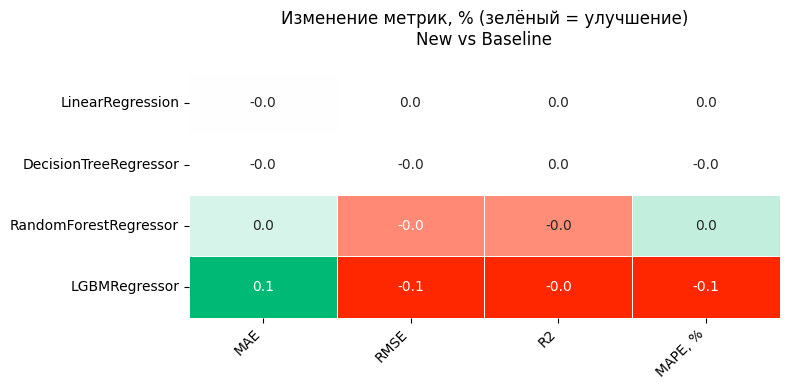

In [33]:
compare_regression_metrics_heatmap(initial_metrics, standard_metrics)

Не улучшилось

#### 2.5.2 С удалением

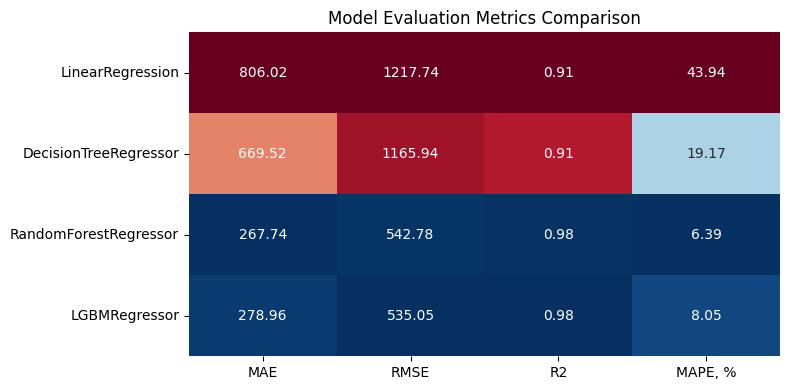

In [34]:
X_standard_del = X.copy()
preprocessor_standard_del = clone(preprocessor)
preprocessor_standard_del.transformers.append(
    ('scaler', StandardScaler(), numeric_cols)
)

standard_del_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X_standard_del, 
    y=y, 
    preprocessor=preprocessor_standard_del, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                                 MAE          RMSE        R2       MAPE, %
 LinearRegression      -5.641916e-13  5.601547e-14  0.000000  3.234309e-14
 DecisionTreeRegressor -0.000000e+00 -0.000000e+00  0.000000 -0.000000e+00
 RandomForestRegressor -3.282849e-02 -6.667712e-02 -0.002463  1.762487e-02
 LGBMRegressor          2.640649e-01  1.165900e-01  0.004198  3.670109e-01)

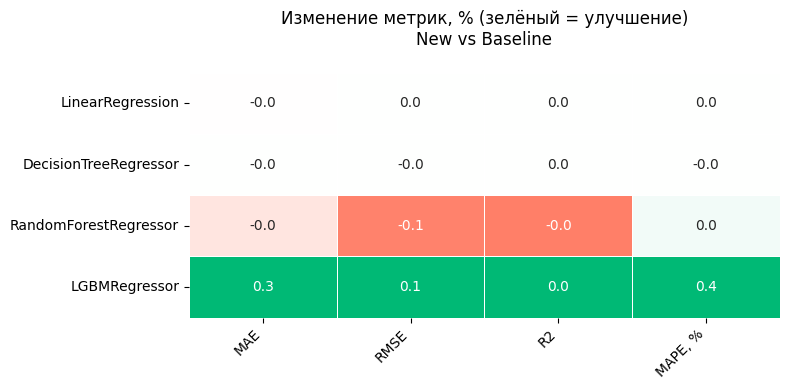

In [35]:
compare_regression_metrics_heatmap(initial_metrics, standard_del_metrics)

Улучшило немного LGBMRegressor 

### 2.6 Нормализация

#### 2.6.1 Без удаления

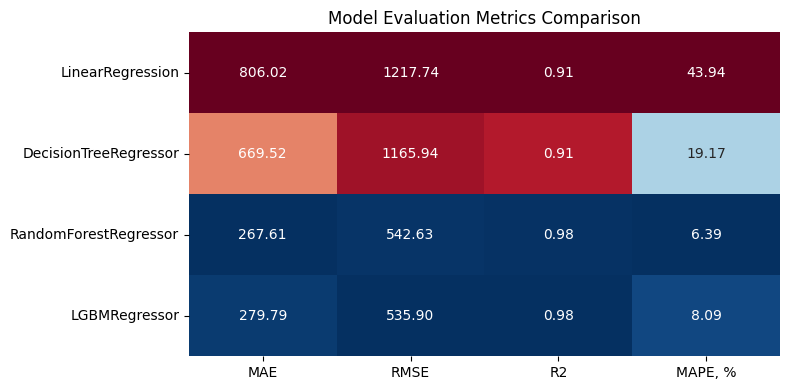

In [36]:
X_minmax = X.copy()
X_minmax[scaled_columns] = X_minmax[numeric_cols]

preprocessor_minmax = clone(preprocessor)
preprocessor_minmax.transformers.append(
    ('scaler', MinMaxScaler(), scaled_columns)
)

minmax_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X_minmax, 
    y=y, 
    preprocessor=preprocessor_minmax, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                                 MAE      RMSE        R2       MAPE, %
 LinearRegression      -3.554407e-12 -0.000000  0.000000  2.732991e-12
 DecisionTreeRegressor -0.000000e+00 -0.000000  0.000000 -0.000000e+00
 RandomForestRegressor  1.558610e-02 -0.038663 -0.001460  1.566831e-02
 LGBMRegressor         -3.482037e-02 -0.042346 -0.001551 -1.271961e-01)

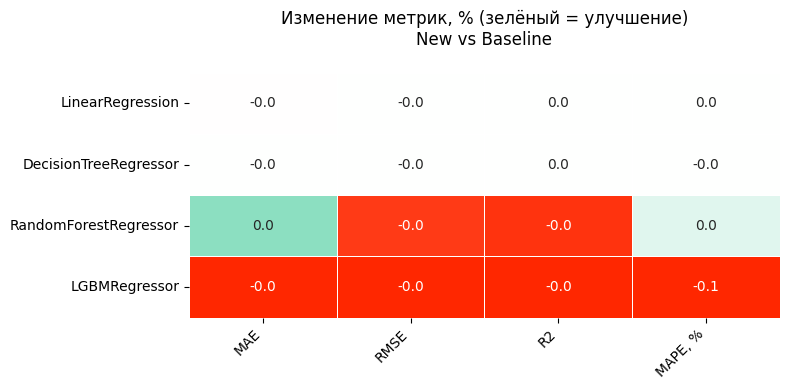

In [37]:
compare_regression_metrics_heatmap(initial_metrics, minmax_metrics)

Почти нет изменений

#### 2.6.2 С удалением

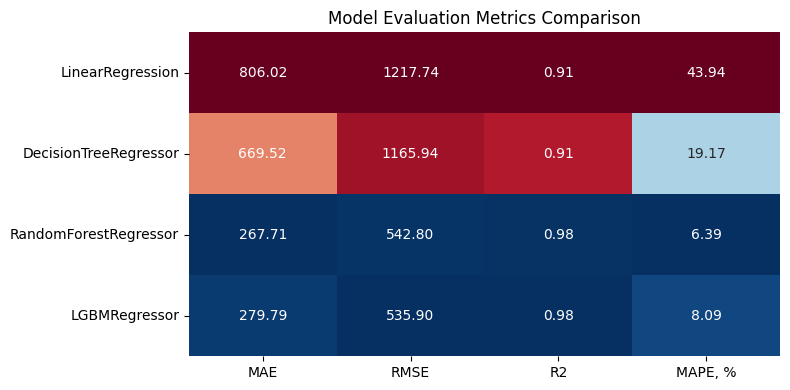

In [38]:
X_minmax_del = X.copy()


preprocessor_minmax_del = clone(preprocessor)
preprocessor_minmax_del.transformers.append(
    ('scaler', MinMaxScaler(), numeric_cols)
)

minmax_del_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X_minmax_del, 
    y=y, 
    preprocessor=preprocessor_minmax_del, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                                 MAE          RMSE            R2       MAPE, %
 LinearRegression       7.052395e-14  4.667956e-13  9.794791e-14 -3.137280e-12
 DecisionTreeRegressor -0.000000e+00 -0.000000e+00  0.000000e+00 -0.000000e+00
 RandomForestRegressor -2.183357e-02 -6.944780e-02 -2.569110e-03  8.102259e-03
 LGBMRegressor         -3.482037e-02 -4.234628e-02 -1.551068e-03 -1.271961e-01)

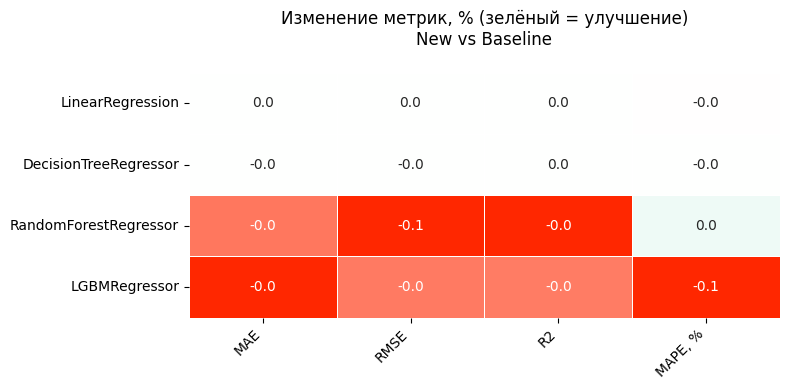

In [39]:
compare_regression_metrics_heatmap(initial_metrics, minmax_del_metrics)

Почти нет изменений

### 2.7 Обработка выбросов

In [40]:
X_no_outliers = X.copy()
for col in ['x', 'y', 'z']:
    X_no_outliers = winsorize_outliers(X_no_outliers, col, lower_bound=3)
X_no_outliers = winsorize_outliers(X_no_outliers, 'y', upper_bound=11)
X_no_outliers = winsorize_outliers(X_no_outliers, 'z', upper_bound=7)

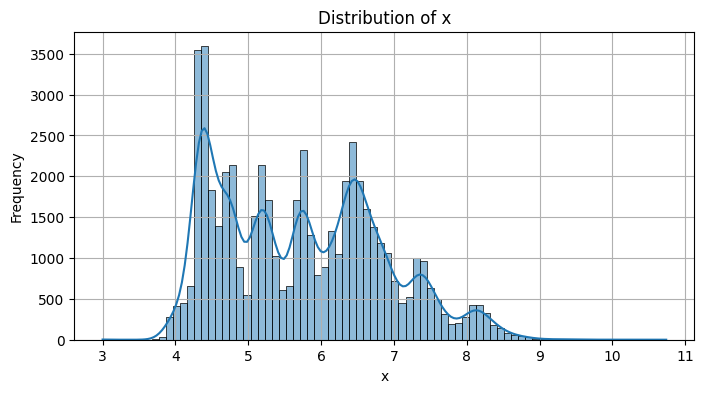

In [41]:
plot_hist_numeric(X_no_outliers, 'x')

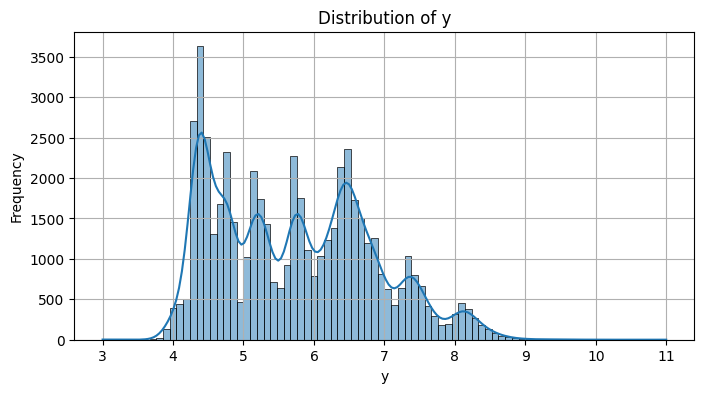

In [42]:
plot_hist_numeric(X_no_outliers, 'y')

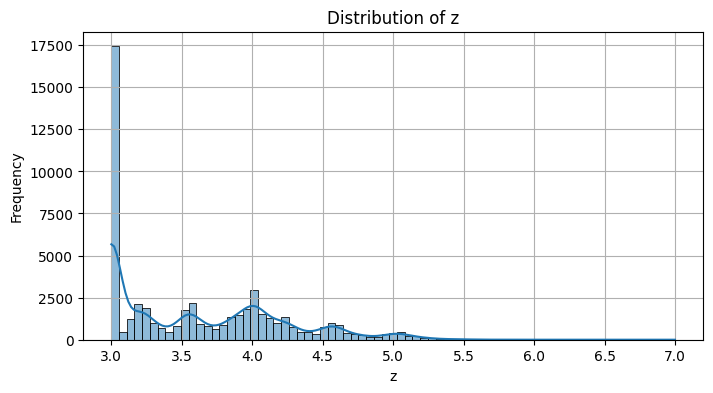

In [43]:
plot_hist_numeric(X_no_outliers, 'z')

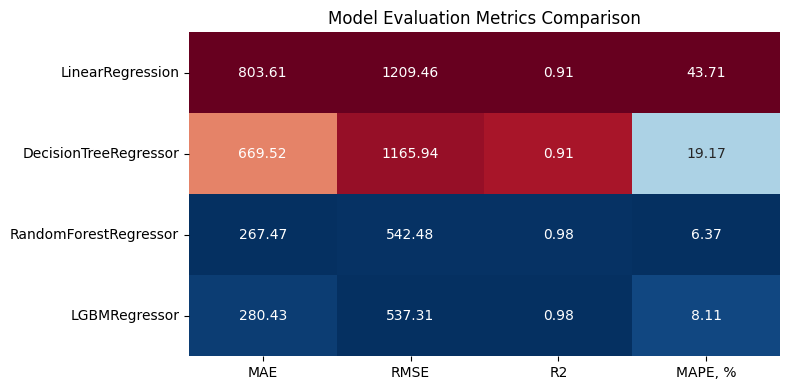

In [44]:
no_outliers_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X_no_outliers, 
    y=y, 
    preprocessor=preprocessor, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                             MAE      RMSE        R2   MAPE, %
 LinearRegression       0.298433  0.679783  0.139558  0.514144
 DecisionTreeRegressor -0.000000 -0.000000  0.000000 -0.000000
 RandomForestRegressor  0.067327 -0.011060 -0.000465  0.286540
 LGBMRegressor         -0.261391 -0.305739 -0.011449 -0.315725)

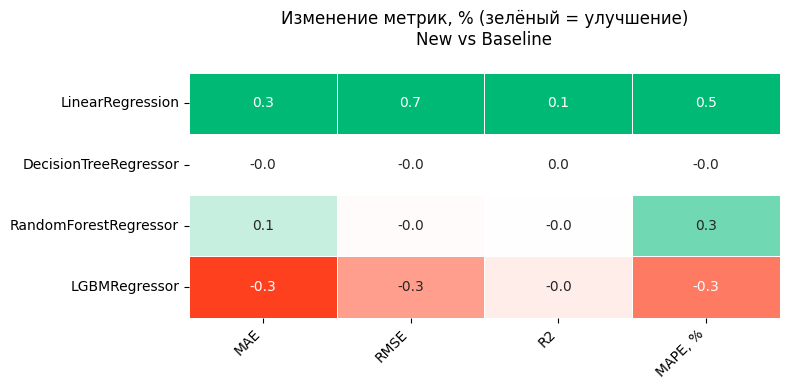

In [45]:
compare_regression_metrics_heatmap(initial_metrics, no_outliers_metrics)

Улучшилась LinearRegression

### 2.9 Кодирование категориальных признаков

#### 2.9.1 Таргетное кодирование

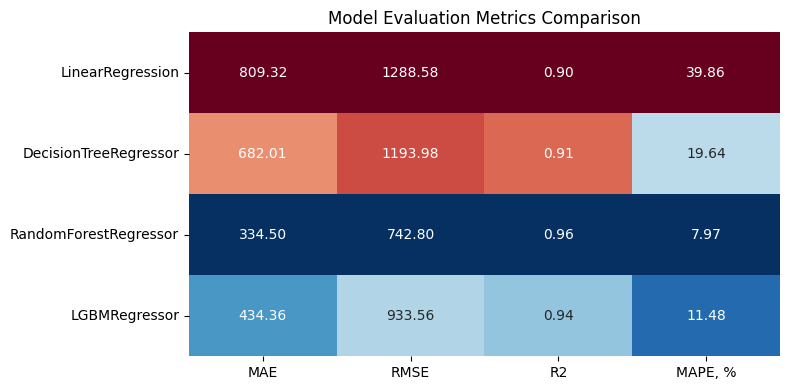

In [46]:
preprocessor_target_encoding = clone(preprocessor)
preprocessor_target_encoding.transformers[0] = (
    'encoder', TargetEncoder(target_type='continuous', random_state=SEED), categorical_cols
)

target_encoder_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X, 
    y=y, 
    preprocessor=preprocessor_target_encoding, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                              MAE       RMSE        R2    MAPE, %
 LinearRegression       -0.409724  -5.817996 -1.231884   9.276893
 DecisionTreeRegressor  -1.866358  -2.405101 -0.455522  -2.447971
 RandomForestRegressor -24.978015 -36.941679 -1.703006 -24.773732
 LGBMRegressor         -55.296573 -74.279197 -3.893519 -42.078578)

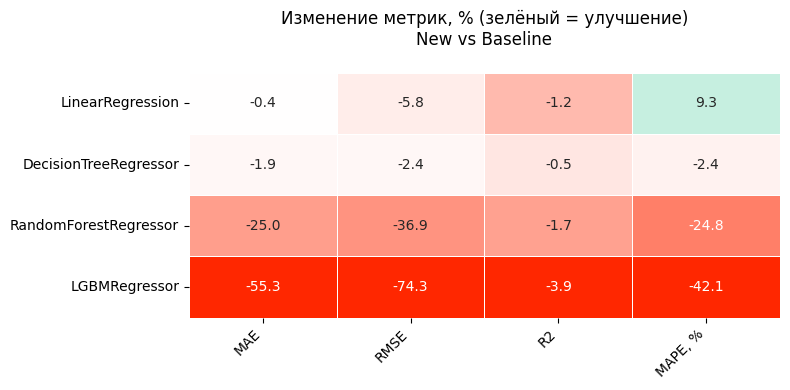

In [47]:
compare_regression_metrics_heatmap(initial_metrics, target_encoder_metrics)

Ухудшение почти по всем метрикам

#### 2.9.2 One-Hot кодирование

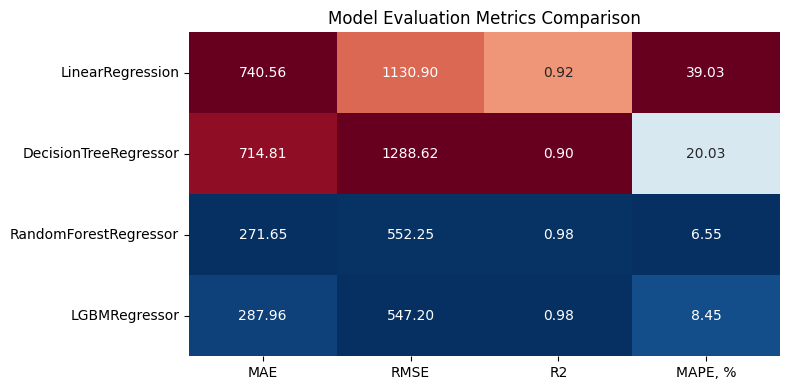

In [48]:
preprocessor_ohe = clone(preprocessor)
preprocessor_ohe.transformers[0] = (
    'encoder', OneHotEncoder(categories=category_orders, sparse_output=False), categorical_cols
)

ohe_metrics = train_evaluate_models_cv_regression(
    models=models, 
    X=X, 
    y=y, 
    preprocessor=preprocessor_ohe, 
    cv=cv, 
    seed=SEED
)

(<Figure size 800x400 with 1 Axes>,
                             MAE       RMSE        R2    MAPE, %
 LinearRegression       8.121251   7.130778  1.413657  11.166588
 DecisionTreeRegressor -6.765558 -10.522224 -2.069160  -4.506736
 RandomForestRegressor -1.493955  -1.811844 -0.069579  -2.574561
 LGBMRegressor         -2.954900  -2.151487 -0.080029  -4.543599)

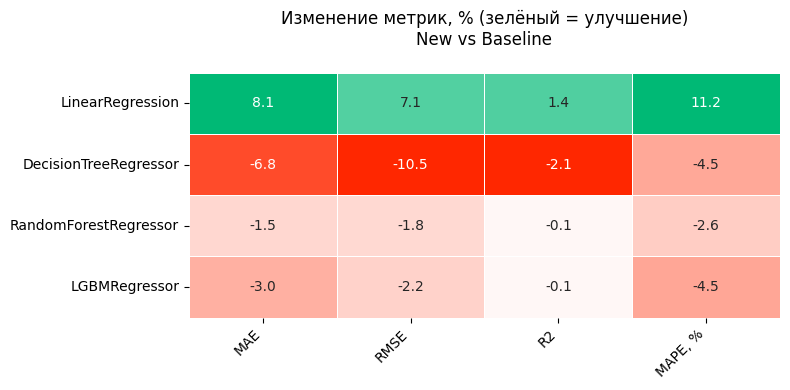

In [49]:
compare_regression_metrics_heatmap(initial_metrics, ohe_metrics)

Заметное улучшение LinearRegression. Но ухудшение DecisionTreeRegressor

### 2.10 Итоговый результат

Ни одно преобразование не улучшило дерево, случайный лес и бустинг: изменения метриr находятся в пределах шума. Заметный выигрыш получила только линейная регрессия от One-Hot кодирования категориальных признаков (она не умеет работать с порядком категорий так же гибко, как деревья). Поэтому для линейной модели применяем One-Hot, а для остальных моделей оставляем бейслайн-предобработку. Логарифм таргета улучшает MAPE, но ухудшает MAE и RMSE, поэтому в итог не включён



In [50]:
X_final = X.copy()

In [51]:
preprocessor_final = clone(preprocessor)
preprocessor_final.transformers[0] = (
    'encoder', OneHotEncoder(categories=category_orders, sparse_output=False), categorical_cols
)

linreg_final_metrics = train_evaluate_models_cv_regression(
    models=[models[0]],   # только LinearRegression
    X=X_final,
    y=y,
    preprocessor=preprocessor_final,
    cv=cv,
    seed=SEED,
    enable_plot=False
)

In [52]:
# Остальные модели остаются как в бейслайне (их метрики уже посчитаны в initial_metrics)
final_metrics = initial_metrics.copy()
final_metrics.loc['LinearRegression'] = linreg_final_metrics.loc['LinearRegression']
final_metrics

,MAE,RMSE,R2,"MAPE, %"
LinearRegression,740.557275,1130.902802,0.919605,39.031479
DecisionTreeRegressor,669.516935,1165.940780,0.914569,19.167084
RandomForestRegressor,267.650813,542.421497,0.981502,6.390235
LGBMRegressor,279.696997,535.671697,0.981964,8.082078


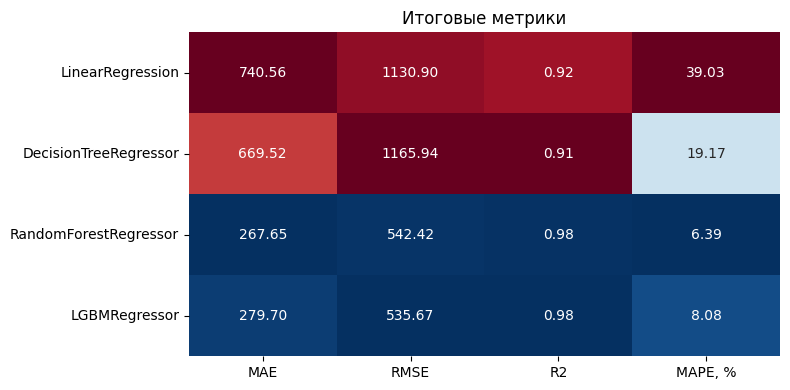

In [53]:
plot_regression_metrics_heatmap(final_metrics, title='Итоговые метрики')

(<Figure size 800x400 with 1 Axes>,
                             MAE      RMSE        R2    MAPE, %
 LinearRegression       8.121251  7.130778  1.413657  11.166588
 DecisionTreeRegressor -0.000000 -0.000000  0.000000  -0.000000
 RandomForestRegressor -0.000000 -0.000000  0.000000  -0.000000
 LGBMRegressor         -0.000000 -0.000000  0.000000  -0.000000)

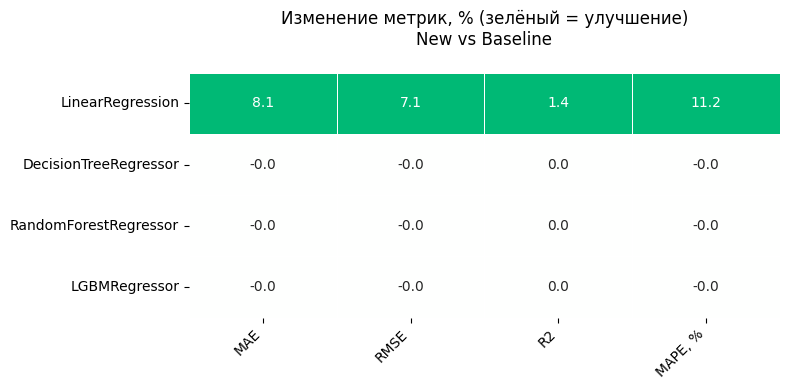

In [54]:
compare_regression_metrics_heatmap(initial_metrics, final_metrics)